In [1]:
!gmx insert-molecules -ci ethane.gro -nmol 250 -box 3 3 3 -o gas_box.gro

            :-) GROMACS - gmx insert-molecules, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/cp2k/Ethane
Command line:
  gmx insert-molecules -ci ethane.gro -nmol 250 -box 3 3 3 -o gas_box.gro

Initialising inter-atomic distances...

         based on residue and atom names, since they could not be
         definitively assigned from the information in your input
         files. These guessed numbers might deviate from the mass
         and radius of the atom type. Please check the output
         files if necessary. Note, that this functionality may
         be removed in a future GROMACS version. Please, consider
         using another file format for your input.

NOTE: From version 5.0 gmx insert-molecules uses the Van der Waals radii
from the source below. This means the results may be different
compared to previous GROMACS versions.

++++ PLEASE RE

In [5]:
!mv em.mdp.txt em.mdp
!mv topol.top.txt topol.top
!gmx grompp -f em.mdp -c gas_box.gro -p topol.top -o em.tpr -maxwarn 1
!gmx mdrun -ntmpi 1 -ntomp 6 -v -deffnm em

                 :-) GROMACS - gmx grompp, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/cp2k/Ethane
Command line:
  gmx grompp -f em.mdp -c gas_box.gro -p topol.top -o em.tpr -maxwarn 1

Setting the LD random seed to -881169217

Generated 36 of the 36 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 36 of the 36 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Ethane'
Analysing residue names:
There are:   250      Other residues
Analysing residues not classified as Protein/DNA/RNA/Water and splitting into groups...
Number of degrees of freedom in T-Coupling group rest is 5997.00
The integrator does not provide a ensemble temperature, there is no system ensemble temperature

The largest distance between excluded atoms is 0.306 nm between atom 1067 and 1071
Calculating fourier grid dimensions fo

In [7]:
!gmx grompp -f nvt.mdp -c em.gro -p topol.top -o nvt.tpr -maxwarn 1
!gmx mdrun -ntmpi 1 -ntomp 6 -v -deffnm nvt

                 :-) GROMACS - gmx grompp, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/cp2k/Ethane
Command line:
  gmx grompp -f nvt.mdp -c em.gro -p topol.top -o nvt.tpr -maxwarn 1

Ignoring obsolete mdp entry 'ns_type'
Setting the LD random seed to -629757445

Generated 36 of the 36 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 36 of the 36 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Ethane'

Setting gen_seed to -545813639

Velocities were taken from a Maxwell distribution at 94 K
Analysing residue names:
There are:   250      Other residues
Analysing residues not classified as Protein/DNA/RNA/Water and splitting into groups...
Number of degrees of freedom in T-Coupling group System is 5997.00

The largest distance between excluded atoms is 0.314 nm between atom 692 and 696

Determi

In [9]:
# 1. Compile and run the NPT equilibration (~15-20 minutes on M-series chip)
!gmx grompp -f npt.mdp -c nvt.gro -t nvt.cpt -p topol.top -o npt.tpr -maxwarn 1
!gmx mdrun -ntmpi 1 -ntomp 6 -v -deffnm npt

# 2. Extract the density to a readable file
!printf "Density\n0\n" | gmx energy -f npt.edr -o density.xvg -xvg none

                 :-) GROMACS - gmx grompp, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/cp2k/Ethane
Command line:
  gmx grompp -f npt.mdp -c nvt.gro -t nvt.cpt -p topol.top -o npt.tpr -maxwarn 1

Ignoring obsolete mdp entry 'ns_type'

WARNING 1 [file npt.mdp]:
  The Berendsen barostat does not generate any strictly correct ensemble,
  and should not be used for new production simulations (in our opinion).
  We recommend using the C-rescale barostat instead.

Setting the LD random seed to -59822085

Generated 36 of the 36 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 36 of the 36 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Ethane'

turning all bonds into constraints...

Taking velocities from 'nvt.gro'
Analysing residue names:
There are:   250      Other residues
Analysing residues not 

In [11]:
# 1. Compile and run the flexible production simulation
!gmx grompp -f production.mdp -c npt.gro -t npt.cpt -p topol.top -o md.tpr -maxwarn 1
!gmx mdrun -ntmpi 1 -ntomp 6 -v -deffnm md

# 2. Extract the Density of States
!echo "2" | gmx dos -f md.trr -s md.tpr -dos dos.xvg -vacf vacf.xvg

                 :-) GROMACS - gmx grompp, 2025.4-Homebrew (-:

Executable:   /opt/homebrew/bin/../Cellar/gromacs/2025.4/bin/gmx
Data prefix:  /opt/homebrew/bin/../Cellar/gromacs/2025.4
Working dir:  /Users/mackenziehenley/cp2k/Ethane
Command line:
  gmx grompp -f production.mdp -c npt.gro -t npt.cpt -p topol.top -o md.tpr -maxwarn 1

Ignoring obsolete mdp entry 'ns_type'
Setting the LD random seed to 2111537062

Generated 36 of the 36 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 36 of the 36 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Ethane'

Taking velocities from 'npt.gro'
Analysing residue names:
There are:   250      Other residues
Analysing residues not classified as Protein/DNA/RNA/Water and splitting into groups...
Number of degrees of freedom in T-Coupling group System is 5997.00

The largest distance between excluded atoms is 0.316 nm between atom 156 and 160

Determining Verlet buffer for a tolerance of 0

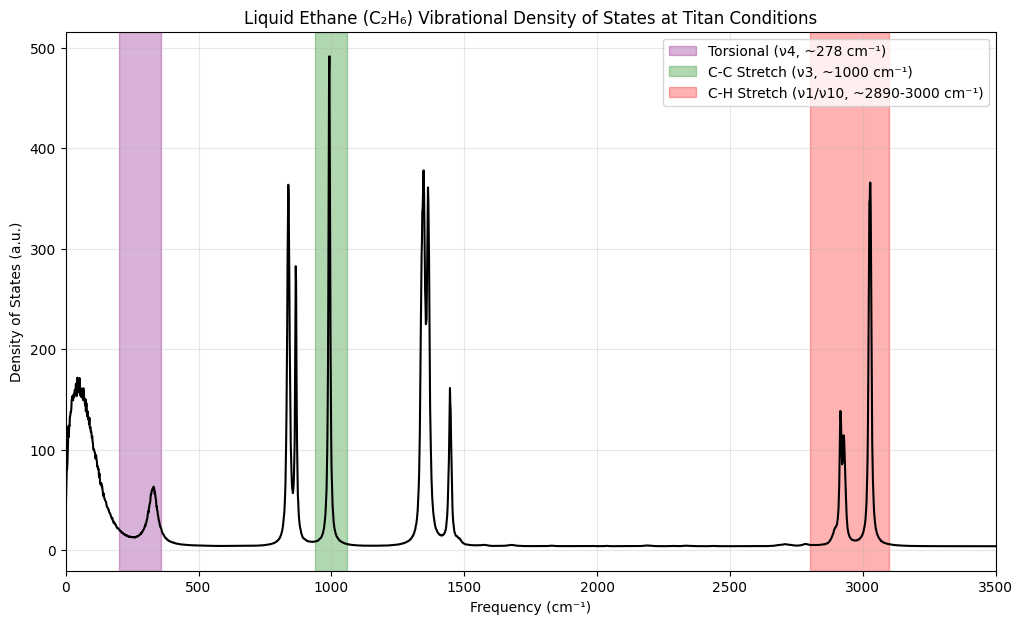

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Filter out metadata headers and grab ONLY the first two columns
with open('dos.xvg', 'r') as f:
    lines = [line.split()[:2] for line in f if not line.startswith(('@', '#'))]

# Load into dataframe
df_dos = pd.DataFrame(lines, columns=['Frequency_THz', 'DOS'], dtype=float)

# CONVERSION: 1 ps^-1 (THz) = 33.35641 cm^-1
df_dos['Frequency_cm-1'] = df_dos['Frequency_THz'] * 33.35641

# Increase figure size slightly to accommodate the legend
plt.figure(figsize=(12, 7))

# Plot the actual DOS data (zorder=3 keeps the line on top of the highlights)
plt.plot(df_dos['Frequency_cm-1'], df_dos['DOS'], color='black', linewidth=1.5, zorder=3)

# Highlight Torsional Mode (~278 cm⁻¹)
plt.axvspan(200, 360, color='purple', alpha=0.3, label='Torsional (ν4, ~278 cm⁻¹)')

# Highlight C-C Stretch (~1000 cm⁻¹)
plt.axvspan(940, 1060, color='green', alpha=0.3, label='C-C Stretch (ν3, ~1000 cm⁻¹)')

# Highlight C-H Stretches (~2890 - 3000 cm⁻¹)
plt.axvspan(2800, 3100, color='red', alpha=0.3, label='C-H Stretch (ν1/ν10, ~2890-3000 cm⁻¹)')

# Formatting
plt.title('Liquid Ethane (C₂H₆) Vibrational Density of States at Titan Conditions')
plt.xlabel('Frequency (cm⁻¹)')
plt.ylabel('Density of States (a.u.)')
plt.xlim(0, 3500)
plt.legend(loc='upper right')
plt.grid(alpha=0.3, zorder=0)

plt.show()